In [1]:
# Import required libraries
import os
import json
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

from openai import OpenAI
from dotenv import load_dotenv

# Load environment variables from .env file
load_dotenv()

# Initialize OpenAI client
client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY"))

# Set default model
MODEL = "gpt-4o-mini"

print("✅ OpenAI client initialized.")



✅ OpenAI client initialized.


In [3]:
def call_openai(prompt, system_message="You are a helpful assistant.", temperature=0.7, max_tokens=None, seed=None):
    """Helper function to call OpenAI API with specified parameters"""
    try:
        params = {
            "model": MODEL,
            "messages": [
                {"role": "system", "content": system_message},
                {"role": "user", "content": prompt}
            ],
            "temperature": temperature
        }

        if max_tokens:
            params["max_tokens"] = max_tokens
        if seed is not None:
            params["seed"] = seed

        response = client.chat.completions.create(**params)
        return response.choices[0].message.content.strip()
    except Exception as e:
        return f"Error: {str(e)}"


def run_multiple(prompt, n=5, max_workers=5, **kwargs):
    """Run the same prompt n times in parallel and return a list of responses"""
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        results = list(executor.map(lambda _: call_openai(prompt, **kwargs), range(n)))
    return results


def display_response(title, response, params=None):
    """Display a response with formatting"""
    print(f"\n{'='*60}")
    print(f"📝 {title}")
    if params:
        print(f"Parameters: {params}")
    print(f"{'='*60}")
    print(response)
    print(f"{'='*60}\n")


def count_tokens_approx(text):
    """Approximate token count (roughly 4 characters per token)"""
    return len(text) // 4


print("✅ Helper functions loaded!")

✅ Helper functions loaded!


In [6]:
# Task 1: Sentiment analysis (version 1, simple zero-shot)
sentiment_prompt_v1 = """
Classify this customer message: "I love this product! It's exactly what I needed."
"""

result = call_openai(sentiment_prompt_v1)
display_response("Sentiment Analysis Result (v1)", result)


📝 Sentiment Analysis Result (v1)
The customer message can be classified as **Positive Feedback** or **Satisfaction**.



In [5]:
# Task 2: Product description (version 1, simple zero-shot)
product_prompt_v1 = """
Create a product description for a wireless mouse that costs $29.99.
"""

result = call_openai(product_prompt_v1)
display_response("Product Description Result (v1)", result)


📝 Product Description Result (v1)
**Product Description: Wireless Precision Pro Mouse - $29.99**

Elevate your computing experience with the Wireless Precision Pro Mouse, designed for both productivity and comfort. Priced at an affordable $29.99, this sleek and stylish mouse combines cutting-edge technology with ergonomic design, making it the perfect accessory for work or play.

**Key Features:**

- **Wireless Freedom:** Say goodbye to tangled cords! The Wireless Precision Pro Mouse connects effortlessly via a reliable 2.4GHz wireless connection, giving you the freedom to move without restrictions.

- **Ergonomic Design:** Crafted with your comfort in mind, the contoured shape fits perfectly in your hand, reducing strain during long hours of use. Enjoy a comfortable grip that keeps you focused and productive.

- **High Precision Tracking:** Equipped with advanced optical sensor technology, this mouse offers smooth and accurate tracking on various surfaces. Whether you're working on a

In [4]:
# Task 3: Data extraction (version 1, simple zero-shot)
extraction_prompt_v1 = """
Extract information from this customer feedback: "I ordered item #12345 on October 5th. The delivery was fast but the packaging was damaged."
"""

result = call_openai(extraction_prompt_v1)
display_response("Data Extraction Result (v1)", result)


📝 Data Extraction Result (v1)
Here is the extracted information from the customer feedback:

- **Order Number:** 12345
- **Order Date:** October 5th
- **Delivery Speed:** Fast
- **Packaging Condition:** Damaged



Part 2:
Step 3:
Cell 1: A helper to analyze the results

In [7]:
def analyze_consistency(responses, title):
    """Show all responses and measure how consistent they are"""
    # Normalize: lowercase, remove spaces and a final period,
    # so "Positive." and "positive" count as the same answer
    normalized = [r.strip().lower().rstrip(".") for r in responses]

    counts = Counter(normalized)
    most_common_answer, frequency = counts.most_common(1)[0]
    consistency = frequency / len(responses) * 100

    word_counts = [len(r.split()) for r in responses]

    print(f"\n{'='*60}")
    print(f"📊 {title}")
    print(f"{'='*60}")
    for i, r in enumerate(responses, 1):
        print(f"\n--- Run {i} ({len(r.split())} words) ---")
        print(r)

    print(f"\n{'-'*60}")
    print(f"Total runs:        {len(responses)}")
    print(f"Unique responses:  {len(counts)}")
    print(f"Consistency:       {consistency:.0f}%")
    print(f"Length range:      {min(word_counts)} to {max(word_counts)} words")
    print(f"{'='*60}\n")

    return {
        "runs": len(responses),
        "unique": len(counts),
        "consistency": consistency,
        "min_words": min(word_counts),
        "max_words": max(word_counts),
    }

Cell 2: Run all three prompts 5 times

In [8]:
# Run each prompt 5 times (in parallel)
results_5 = {
    "Sentiment Analysis": run_multiple(sentiment_prompt_v1, n=5),
    "Product Description": run_multiple(product_prompt_v1, n=5),
    "Data Extraction": run_multiple(extraction_prompt_v1, n=5),
}

# Analyze each one and save the numbers
analysis_5 = {}
for task_name, responses in results_5.items():
    analysis_5[task_name] = analyze_consistency(responses, f"{task_name} (v1, 5 runs)")


📊 Sentiment Analysis (v1, 5 runs)

--- Run 1 (6 words) ---
This customer message is positive feedback.

--- Run 2 (12 words) ---
The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

--- Run 3 (12 words) ---
This customer message can be classified as **positive feedback** or **customer satisfaction**.

--- Run 4 (12 words) ---
The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

--- Run 5 (12 words) ---
The customer message can be classified as **positive feedback** or **customer satisfaction**.

------------------------------------------------------------
Total runs:        5
Unique responses:  4
Consistency:       40%
Length range:      6 to 12 words


📊 Product Description (v1, 5 runs)

--- Run 1 (276 words) ---
**Product Description: Wireless Precision Mouse**

Elevate your productivity and streamline your workspace with our Wireless Precision Mouse, designed for both comfort and performance. Priced at just

Step 3:


## Step 3: Results (v1, 5 runs)

| Task | Unique responses | Consistency | Length range | Format consistent? 
| Sentiment Analysis | 4 | 40% | 6–12 words | No |
| Product Description | 5 | 20% | 251–308 words | Partly (same structure) |
| Data Extraction | 3 | 60% | 26 words | Mostly |

### Sentiment Analysis
- **Format:** Not consistent. Answers are full sentences, using quotes in some runs and bold text in others.
- **Content:** The meaning is always positive, but the model invents its own labels ("positive feedback", "customer satisfaction") and often gives two labels at once.
- **Variations observed:** label wording, number of labels, formatting (quotes vs bold), length.
- **Root cause:** the prompt does not define the categories or the output format.

### Product Description
- **Format:** Mostly consistent structure (title, intro, Key Features list, call to action), but the title format varies and one run adds an extra section.
- **Content:** Not consistent. The product name changes, and the model invents specifications that contradict each other (AA vs AAA battery, 12 vs 18 months battery life, programmable buttons in some runs only).
- **Variations observed:** product name, specs, extra sections, length (251–308 words).
- **Root cause:** no length limit, no structure rules, and no list of real product features, so the model fills the gaps by inventing facts.
- **Note:** 20% is the minimum possible score with 5 runs. Exact-match consistency is not a useful measure for creative text.

### Data Extraction
- **Format:** Mostly consistent (intro sentence + 4 bullet points), but not machine-readable (Markdown, not JSON).
- **Content:** Values are consistent (#12345, October 5th, Fast, Damaged). The order date was correctly identified.
- **Variations observed:** field names ("Delivery Speed" vs "Delivery Experience", "Order Number" vs "Order Item") and small Markdown differences.
- **Root cause:** the prompt does not specify which fields to extract, what to call them, or the output format.
- **Hidden issue:** "#12345" is labeled as an order number, but the text says it is an item number.

Step 4:


Cell 1: Run all three prompts 10 times

In [9]:
# Run each prompt 10 times (in parallel)
results_10 = {
    "Sentiment Analysis": run_multiple(sentiment_prompt_v1, n=10),
    "Product Description": run_multiple(product_prompt_v1, n=10),
    "Data Extraction": run_multiple(extraction_prompt_v1, n=10),
}

# Analyze each one and save the numbers
analysis_10 = {}
for task_name, responses in results_10.items():
    analysis_10[task_name] = analyze_consistency(responses, f"{task_name} (v1, 10 runs)")


📊 Sentiment Analysis (v1, 10 runs)

--- Run 1 (11 words) ---
The customer message can be classified as "Positive Feedback" or "Satisfaction."

--- Run 2 (12 words) ---
The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

--- Run 3 (12 words) ---
The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

--- Run 4 (12 words) ---
The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

--- Run 5 (12 words) ---
This customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

--- Run 6 (12 words) ---
The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

--- Run 7 (9 words) ---
The customer message can be classified as positive feedback.

--- Run 8 (12 words) ---
The customer message can be classified as **positive feedback** or **customer satisfaction**.

--- Run 9 (12 words) ---
The customer message can be classified as **

Cell 2: Compare 5 runs vs 10 runs

In [10]:
print(f"{'Task':<22}{'5 runs':>10}{'10 runs':>10}{'Change':>10}")
print("-" * 52)

for task_name in analysis_5:
    c5 = analysis_5[task_name]["consistency"]
    c10 = analysis_10[task_name]["consistency"]
    change = c10 - c5
    print(f"{task_name:<22}{c5:>9.0f}%{c10:>9.0f}%{change:>+9.0f}%")

print()
print(f"{'Task':<22}{'Unique (5)':>12}{'Unique (10)':>13}")
print("-" * 47)
for task_name in analysis_5:
    print(f"{task_name:<22}{analysis_5[task_name]['unique']:>12}{analysis_10[task_name]['unique']:>13}")

Task                      5 runs   10 runs    Change
----------------------------------------------------
Sentiment Analysis           40%       40%       +0%
Product Description          20%       10%      -10%
Data Extraction              60%       50%      -10%

Task                    Unique (5)  Unique (10)
-----------------------------------------------
Sentiment Analysis               4            6
Product Description              5           10
Data Extraction                  3            5


Cell 3: Find NEW answers that didn’t appear in the 5-run test

In [11]:
def normalize(text):
    return text.strip().lower().rstrip(".")

for task_name in results_5:
    old_answers = set(normalize(r) for r in results_5[task_name])
    new_answers = set(normalize(r) for r in results_10[task_name]) - old_answers

    print(f"\n{'='*60}")
    print(f"🔍 {task_name}: {len(new_answers)} new answer(s) not seen in 5-run test")
    print(f"{'='*60}")
    for answer in new_answers:
        print(f"- {answer[:150]}")


🔍 Sentiment Analysis: 3 new answer(s) not seen in 5-run test
- the customer message can be classified as positive feedback
- this customer message can be classified as "positive feedback" or "customer satisfaction."
- the customer message can be classified as "positive feedback" or "satisfaction."

🔍 Product Description: 10 new answer(s) not seen in 5-run test
- **product description: wireless ergonomic mouse - $29.99**

elevate your computing experience with our wireless ergonomic mouse, designed to combine s
- **product description: wireless comfort mouse**

elevate your computing experience with our wireless comfort mouse, designed for seamless navigation a
- **product description: wireless freedom: sleek & ergonomic wireless mouse - $29.99**

elevate your computing experience with our state-of-the-art wire
- **product description: wireless precision mouse**

elevate your computing experience with our wireless precision mouse, designed for both comfort and 
- **product description:

Observations:

## Step 4: Results (v1, 10 runs)

| Task | Consistency (5) | Consistency (10) | Unique (5) | Unique (10) | Length range (10) |
|---|---|---|---|---|---|
| Sentiment Analysis | 40% | 40% | 4 | 6 | 9–12 words |
| Product Description | 20% | 10% | 5 | 10 | 267–359 words |
| Data Extraction | 60% | 50% | 3 | 5 | 26 words |

### New failure patterns found with 10 runs
- **Sentiment:** New label variations appeared ("Satisfaction" instead of "Customer Satisfaction") and, for the first time, a single-label answer. The model still never answered with a simple label like "Positive".
- **Product Description:**
  - The length range became wider (267–359 words, compared to 251–308).
  - More product names appeared (Ergonomic, Freedom, a generic "Wireless Mouse") and an invented brand name ("SwiftConnect").
  - One run used a completely different structure (separate Product Name / Price / Description sections), and new sections appeared ("Perfect For", "Compatibility").
  - More contradicting invented facts: range (30 vs 33 feet), compatibility (with or without Linux), and battery type (replaceable AA battery vs "recharging").
- **Data Extraction:**
  - The item number was given 4 different field names (Order Number, Order Item, Item Number, Order ID).
  - One run changed the last field to "Issue: Damaged packaging" instead of "Packaging Condition: Damaged".
  - One run dropped the bold formatting and used plain text.

### Conclusion
More runs revealed more problems. Consistency stayed the same or dropped for every task, and the number of unique answers increased for every task. Some failure patterns (a new structure, new field names, a new formatting style, contradicting facts) only appeared with 10 runs, which shows that 5 runs are not enough to judge whether a prompt is reliable. The growing number of unique answers shows that the v1 prompts do not limit the possible outputs.

Step 5:

Cell 1: Run all three prompts 15 times

In [12]:
prompts_v1 = {
    "Sentiment Analysis": sentiment_prompt_v1,
    "Product Description": product_prompt_v1,
    "Data Extraction": extraction_prompt_v1,
}

results_15 = {}
for task_name, prompt in prompts_v1.items():
    print(f"⏳ Running {task_name} 15 times...")
    results_15[task_name] = run_multiple(prompt, n=15)
    time.sleep(2)  # pause 2 seconds before the next task

analysis_15 = {}
for task_name, responses in results_15.items():
    analysis_15[task_name] = analyze_consistency(responses, f"{task_name} (v1, 15 runs)")

⏳ Running Sentiment Analysis 15 times...
⏳ Running Product Description 15 times...
⏳ Running Data Extraction 15 times...

📊 Sentiment Analysis (v1, 15 runs)

--- Run 1 (12 words) ---
The customer message can be classified as **positive feedback** or **customer satisfaction**.

--- Run 2 (12 words) ---
This customer message can be classified as **positive feedback** or **customer satisfaction**.

--- Run 3 (9 words) ---
The customer message can be classified as **Positive Feedback**.

--- Run 4 (12 words) ---
The customer message can be classified as **positive feedback** or **customer satisfaction**.

--- Run 5 (12 words) ---
The customer message can be classified as **positive feedback** or **customer satisfaction**.

--- Run 6 (11 words) ---
The customer message can be classified as "Positive Feedback" or "Satisfaction."

--- Run 7 (13 words) ---
This customer message can be classified as positive feedback or a positive review.

--- Run 8 (9 words) ---
The customer message can be cla

Cell 2: Summary table of all three tests (5, 10, 15 runs)

In [13]:
import pandas as pd

rows = []
for task_name in analysis_5:
    for runs, analysis in [(5, analysis_5), (10, analysis_10), (15, analysis_15)]:
        a = analysis[task_name]
        rows.append({
            "Task": task_name,
            "Runs": runs,
            "Unique responses": a["unique"],
            "Consistency %": round(a["consistency"]),
            "Length range (words)": f"{a['min_words']}–{a['max_words']}",
        })

summary_v1 = pd.DataFrame(rows)
summary_v1

,Task,Runs,Unique responses,Consistency %,Length range (words)
0,Sentiment Analysis,5,4,40,6–12
1,Sentiment Analysis,10,6,40,9–12
2,Sentiment Analysis,15,8,33,9–13
3,Product Description,5,5,20,251–308
4,Product Description,10,10,10,267–359
5,Product Description,15,15,7,245–326
6,Data Extraction,5,3,60,26–26
7,Data Extraction,10,5,50,26–26
8,Data Extraction,15,7,47,25–29


Cell 3: Automatic failure checks

In [14]:
import re

def show_checks(title, checks, n):
    """Print how many runs show each failure pattern"""
    print(f"\n{'='*60}")
    print(f"🔎 {title} ({n} runs)")
    print(f"{'='*60}")
    for check_name, count in checks.items():
        print(f"{check_name:<45} {count:>3} / {n}")


# --- Sentiment Analysis checks ---
s = results_15["Sentiment Analysis"]
show_checks("Sentiment Analysis", {
    "One-word answer": sum(len(r.split()) == 1 for r in s),
    "Simple label only (positive/negative/neutral)": sum(normalize(r) in ["positive", "negative", "neutral"] for r in s),
    "Gives two labels ('or')": sum(" or " in r.lower() for r in s),
    "Uses Markdown bold (**)": sum("**" in r for r in s),
}, len(s))


# --- Product Description checks ---
p = results_15["Product Description"]
show_checks("Product Description", {
    "Longer than 150 words": sum(len(r.split()) > 150 for r in p),
    "Mentions the price ($29.99)": sum("$29.99" in r for r in p),
    "Invents battery details": sum("battery" in r.lower() for r in p),
    "Invents a range (feet)": sum("feet" in r.lower() for r in p),
    "Invents DPI settings": sum("dpi" in r.lower() for r in p),
}, len(p))

print("\nFirst line (title) of each run:")
for title, count in Counter(r.split("\n")[0] for r in p).items():
    print(f"  {count}x  {title}")


# --- Data Extraction checks ---
def is_valid_json(text):
    try:
        json.loads(text)
        return True
    except json.JSONDecodeError:
        return False

def label_for_item(text):
    """Find the field name the model used for #12345"""
    for line in text.split("\n"):
        if "12345" in line and ":" in line:
            return line.split(":")[0].strip("-* ").strip()
    return "(not found)"

e = results_15["Data Extraction"]
show_checks("Data Extraction", {
    "Valid JSON (machine-readable)": sum(is_valid_json(r) for r in e),
    "Starts with an intro sentence": sum(r.lower().startswith("here is") for r in e),
    "Mentions a 'delivery date' (mix-up)": sum("delivery date" in r.lower() for r in e),
}, len(e))

print("\nField name used for #12345:")
for label, count in Counter(label_for_item(r) for r in e).items():
    print(f"  {count}x  {label}")


🔎 Sentiment Analysis (15 runs)
One-word answer                                 0 / 15
Simple label only (positive/negative/neutral)   0 / 15
Gives two labels ('or')                        12 / 15
Uses Markdown bold (**)                        11 / 15

🔎 Product Description (15 runs)
Longer than 150 words                          15 / 15
Mentions the price ($29.99)                    15 / 15
Invents battery details                        15 / 15
Invents a range (feet)                         10 / 15
Invents DPI settings                            6 / 15

First line (title) of each run:
  1x  **Product Description: Wireless Precision Mouse – $29.99**
  1x  **Product Name:** SwiftClick Wireless Mouse
  1x  **Product Description: Wireless SleekMouse Pro**
  1x  **Product Description: Wireless Freedom Mouse - $29.99**
  3x  **Product Description: Wireless Precision Mouse**
  1x  **Product Description: Wireless Freedom: Sleek & Stylish Wireless Mouse**
  1x  **Product Name: SleekWave Wirele

Failure Analysis Document

## Step 5: Failure Analysis (v1, 15 runs)

### Summary

| Task | Consistency (5 / 10 / 15) | Unique (5 / 10 / 15) | Length (15) |
|---|---|---|---|
| Sentiment Analysis | 40% / 40% / 33% | 4 / 6 / 8 | 9–13 words |
| Product Description | 20% / 10% / 7% | 5 / 10 / 15 | 245–326 words |
| Data Extraction | 60% / 50% / 47% | 3 / 5 / 7 | 25–29 words |

Consistency dropped and unique answers grew with more runs. No prompt is close to the 80% target.
Every product description was unique, so for that task length, structure and facts matter more than the %.

### Main failure patterns

| Task | Failure | How often | Root cause |
|---|---|---|---|
| Sentiment | No simple label (Positive/Negative/Neutral), always a full sentence | 15 / 15 | No labels or format defined |
| Sentiment | Two labels at once ("... or ...") | 12 / 15 | No "single answer" rule |
| Product | Too long (over 150 words) | 15 / 15 | No length limit |
| Product | Different product name / title | 12 titles in 15 runs | No name given |
| Product | Invented, contradicting specs (battery, range, DPI) and a fake promotion | 15 / 15 | No feature list, no "don't invent" rule |
| Product | Extra or different sections | 7 / 15 | No structure defined |
| Extraction | Not JSON, always an intro sentence | 15 / 15 | No output format defined |
| Extraction | Field names and value format change (Order vs Item Number, # dropped) | 6 / 15 | No field names or value format defined |

### Key findings
- **Sentiment:** the meaning was always correct (positive), but the format was never usable by a program.
- **Product:** the most serious problem is hallucination, e.g. battery included vs not included, AA battery vs rechargeable.
- **Extraction:** the values were always correct and the order date was never confused, but the output isn't machine-readable.

### What to fix in Part 3
- **Sentiment (Step 6):** allow only Positive, Negative or Neutral; one word, no explanation.
- **Product (Step 7):** give a name and real features, set a length limit, a fixed structure and a style; forbid invented details.
- **Extraction (Step 8):** JSON only, with fixed field names and value format; no intro text.

Part 3: Iteration 1 - Rewriting Simple Prompts


Cell 1: Improve the sentiment analysis prompt

In [15]:
customer_message = "I love this product! It's exactly what I needed."

sentiment_prompt_v2 = f"""
Classify the sentiment of the customer message below.

Choose exactly ONE of these labels:
- Positive
- Negative
- Neutral

Rules:
- Respond with only the label, as a single word.
- Do not add any explanation, punctuation, or formatting.

Customer message: "{customer_message}"
"""

result = call_openai(sentiment_prompt_v2)
display_response("Sentiment Analysis Result (v2)", result)


📝 Sentiment Analysis Result (v2)
Positive



Cell 2: Test it 15 times

In [16]:
results_sentiment_v2 = run_multiple(sentiment_prompt_v2, n=15)
analysis_sentiment_v2 = analyze_consistency(results_sentiment_v2, "Sentiment Analysis (v2, 15 runs)")

s2 = results_sentiment_v2
show_checks("Sentiment Analysis v2", {
    "One-word answer": sum(len(r.split()) == 1 for r in s2),
    "Simple label only (positive/negative/neutral)": sum(normalize(r) in ["positive", "negative", "neutral"] for r in s2),
    "Gives two labels ('or')": sum(" or " in r.lower() for r in s2),
    "Uses Markdown bold (**)": sum("**" in r for r in s2),
}, len(s2))


📊 Sentiment Analysis (v2, 15 runs)

--- Run 1 (1 words) ---
Positive

--- Run 2 (1 words) ---
Positive

--- Run 3 (1 words) ---
Positive

--- Run 4 (1 words) ---
Positive

--- Run 5 (1 words) ---
Positive

--- Run 6 (1 words) ---
Positive

--- Run 7 (1 words) ---
Positive

--- Run 8 (1 words) ---
Positive

--- Run 9 (1 words) ---
Positive

--- Run 10 (1 words) ---
Positive

--- Run 11 (1 words) ---
Positive

--- Run 12 (1 words) ---
Positive

--- Run 13 (1 words) ---
Positive

--- Run 14 (1 words) ---
Positive

--- Run 15 (1 words) ---
Positive

------------------------------------------------------------
Total runs:        15
Unique responses:  1
Consistency:       100%
Length range:      1 to 1 words


🔎 Sentiment Analysis v2 (15 runs)
One-word answer                                15 / 15
Simple label only (positive/negative/neutral)  15 / 15
Gives two labels ('or')                         0 / 15
Uses Markdown bold (**)                         0 / 15


Cell 3: Compare v1 vs v2

In [17]:
v1 = analysis_15["Sentiment Analysis"]
v2 = analysis_sentiment_v2

print(f"{'Metric':<20}{'v1':>10}{'v2':>10}")
print("-" * 40)
print(f"{'Consistency':<20}{v1['consistency']:>9.0f}%{v2['consistency']:>9.0f}%")
print(f"{'Unique responses':<20}{v1['unique']:>10}{v2['unique']:>10}")
print(f"{'Length (words)':<20}{str(v1['min_words'])+'–'+str(v1['max_words']):>10}{str(v2['min_words'])+'–'+str(v2['max_words']):>10}")

Metric                      v1        v2
----------------------------------------
Consistency                33%      100%
Unique responses             8         1
Length (words)            9–13       1–1


Analysis:


## Step 6: Sentiment Analysis v2

**Changes from v1:**
- Clear task: classify the *sentiment*
- Fixed label set: Positive, Negative, Neutral
- Constraint: exactly one label, single word, no explanation or formatting
- Message stored in a variable (instructions separated from data)

| Metric | v1 | v2 |
|---|---|---|
| Consistency (15 runs) | 33% | 100% |
| Unique responses | 8 | 1 |
| Length (words) | 9–13 | 1 |
| One-word answer | 0 / 15 | 15 / 15 |
| Simple label only | 0 / 15 | 15 / 15 |
| Two labels ("or") | 12 / 15 | 0 / 15 |
| Markdown bold | 11 / 15 | 0 / 15 |

**Result:** Adding clear instructions, a fixed label set and output constraints raised consistency from 33% to 100%. All failure patterns from v1 were removed. This shows that the v1 failures were caused by the prompt, not by the model's understanding: the sentiment was always recognized correctly, but the model didn't know which format to use.

**Limitation:** v2 was only tested on one clearly positive message. Harder cases (mixed or neutral messages) still need to be tested in Step 12.

Step 7: Improve Product Description Prompt


Cell 1: The improved prompt (v2)

In [18]:
product_name = "Wireless Precision Mouse"
price = "$29.99"
features = [
    "2.4 GHz wireless connection with a plug-and-play USB receiver",
    "Ergonomic, contoured shape for comfortable all-day use",
    "Quiet click buttons",
]

features_text = "\n".join(f"- {f}" for f in features)

product_prompt_v2 = f"""
Write a product description for an online shop.

Product information:
- Name: {product_name}
- Price: {price}
- Features:
{features_text}

Structure (follow exactly):
1. First line: the product name and price, written as: {product_name} - {price}
2. One short paragraph of 2 sentences introducing the product.
3. Exactly 3 bullet points, one for each feature, each starting with "- ".

Length: 50 to 80 words in total.

Style: professional and friendly. No exaggerated claims (like "ultimate" or "best ever").

Rules:
- Use ONLY the information provided above. Do not invent any specifications, battery details, compatibility, colors, or promotions.
- Mention the price only once, in the first line.
- Do not use Markdown formatting (no ** or #).
"""

result = call_openai(product_prompt_v2)
display_response("Product Description Result (v2)", result)


📝 Product Description Result (v2)
Wireless Precision Mouse - $29.99  
Experience seamless navigation with the Wireless Precision Mouse, designed to enhance your productivity. Its ergonomic shape ensures comfortable use throughout the day.

- 2.4 GHz wireless connection with a plug-and-play USB receiver  
- Ergonomic, contoured shape for comfortable all-day use  
- Quiet click buttons



Cell 2: Test v2 15 times

In [19]:
results_product_v2 = run_multiple(product_prompt_v2, n=15)
analysis_product_v2 = analyze_consistency(results_product_v2, "Product Description (v2, 15 runs)")


📊 Product Description (v2, 15 runs)

--- Run 1 (52 words) ---
Wireless Precision Mouse - $29.99  
Experience seamless navigation with our Wireless Precision Mouse, designed for both productivity and comfort. Its ergonomic shape ensures you can work comfortably all day long.  

- 2.4 GHz wireless connection with a plug-and-play USB receiver  
- Ergonomic, contoured shape for comfortable all-day use  
- Quiet click buttons

--- Run 2 (56 words) ---
Wireless Precision Mouse - $29.99  
Experience seamless navigation with the Wireless Precision Mouse, designed for both comfort and efficiency. Perfect for everyday tasks, this mouse will enhance your productivity without the hassle of wires.  

- 2.4 GHz wireless connection with a plug-and-play USB receiver  
- Ergonomic, contoured shape for comfortable all-day use  
- Quiet click buttons

--- Run 3 (52 words) ---
Wireless Precision Mouse - $29.99  
Enhance your computing experience with our Wireless Precision Mouse, designed for comfort and

Cell 3: Structure and fact checks (v1 vs v2)

In [20]:
def product_checks(responses):
    """Check each description against the rules in the v2 prompt"""
    expected_title = f"{product_name} - {price}"
    invented_words = ["battery", "feet", "dpi", "shipping", "linux", "color", "colour"]

    checks = {
        "Length 50–80 words": [],
        "Correct title line": [],
        "Exactly 3 bullet points": [],
        "Price mentioned once": [],
        "No Markdown (**)": [],
        "No invented details": [],
    }

    for r in responses:
        lines = [line.strip() for line in r.split("\n") if line.strip()]
        checks["Length 50–80 words"].append(50 <= len(r.split()) <= 80)
        checks["Correct title line"].append(lines[0] == expected_title)
        checks["Exactly 3 bullet points"].append(sum(line.startswith("- ") for line in lines) == 3)
        checks["Price mentioned once"].append(r.count(price) == 1)
        checks["No Markdown (**)"].append("**" not in r)
        checks["No invented details"].append(not any(w in r.lower() for w in invented_words))

    counts = {name: sum(values) for name, values in checks.items()}
    all_passed = sum(all(run) for run in zip(*checks.values()))
    counts["✅ Passes ALL rules"] = all_passed
    return counts


v1_checks = product_checks(results_15["Product Description"])
v2_checks = product_checks(results_product_v2)

print(f"{'Check':<28}{'v1':>8}{'v2':>8}")
print("-" * 44)
for name in v1_checks:
    print(f"{name:<28}{v1_checks[name]:>5}/15{v2_checks[name]:>5}/15")

Check                             v1      v2
--------------------------------------------
Length 50–80 words              0/15   14/15
Correct title line              0/15   15/15
Exactly 3 bullet points         0/15   15/15
Price mentioned once            0/15   15/15
No Markdown (**)                0/15   15/15
No invented details             0/15   15/15
✅ Passes ALL rules              0/15   14/15


Observation:


## Step 7: Product Description v2

**Changes from v1:**
- Real product information provided (name, price, 3 features)
- Fixed structure: title line, 2-sentence paragraph, 3 bullet points
- Length limit: 50–80 words
- Style: professional and friendly, no exaggerated claims
- Rules: use only the given information, price once, no Markdown

| Check | v1 | v2 |
|---|---|---|
| Length 50–80 words | 0 / 15 | 14 / 15 |
| Correct title line | 0 / 15 | 15 / 15 |
| Exactly 3 bullet points | 0 / 15 | 15 / 15 |
| Price mentioned once | 0 / 15 | 15 / 15 |
| No Markdown | 0 / 15 | 15 / 15 |
| No invented details | 0 / 15 | 15 / 15 |
| **Passes ALL rules** | **0 / 15** | **14 / 15 (93%)** |
| Length range (words) | 245–326 | 49–59 |

**Result:** Giving the model real product information, a fixed structure, a length limit and a "use only this information" rule raised the rule pass rate from 0% to 93%. Hallucinations were completely removed (0 invented details). The only failure was one run with 49 words, just below the 50-word minimum. Exact-match consistency is still 7%, which is expected for creative text, since the wording changes in every run.

**Remaining issues (to fix in Step 11):**
- The bullet points copy the feature list word-for-word in 14/15 runs instead of describing benefits.
- The intro is generic and repetitive (12/15 start with "Experience seamless navigation").
- Some runs add vague claims not in the product information ("advanced technology", "reliable").
- All runs are at the low end of the length range, so occasionally a run falls just below the minimum.

Step 8: Improve Data Extraction Prompt


Cell 1: The improved prompt (v2)

In [21]:
feedback = "I ordered item #12345 on October 5th. The delivery was fast but the packaging was damaged."

extraction_prompt_v2 = f"""
Extract information from the customer feedback below.

Return the result as JSON with exactly these 4 fields:
- "item_number": the item number, including the # symbol (for example "#12345")
- "order_date": the date the order was placed, exactly as written in the text
- "delivery_speed": one of "fast", "slow", or "normal"
- "packaging_condition": one of "damaged" or "intact"

Rules:
- If a piece of information is not mentioned, use null.
- Return ONLY the JSON object. No introduction, no explanation, no Markdown, no code blocks.

Customer feedback: "{feedback}"
"""

result = call_openai(extraction_prompt_v2)
display_response("Data Extraction Result (v2)", result)


📝 Data Extraction Result (v2)
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}



Cell 2: Test v2 15 times

In [22]:
results_extraction_v2 = run_multiple(extraction_prompt_v2, n=15)
analysis_extraction_v2 = analyze_consistency(results_extraction_v2, "Data Extraction (v2, 15 runs)")


📊 Data Extraction (v2, 15 runs)

--- Run 1 (11 words) ---
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}

--- Run 2 (11 words) ---
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}

--- Run 3 (11 words) ---
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}

--- Run 4 (11 words) ---
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}

--- Run 5 (11 words) ---
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}

--- Run 6 (11 words) ---
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}

--- Run 7 (11 words) ---
{
  "item_number": "#12345",
  "ord

Cell 3: JSON and accuracy checks (v1 vs v2)

In [23]:
expected = {
    "item_number": "#12345",
    "order_date": "October 5th",
    "delivery_speed": "fast",
    "packaging_condition": "damaged",
}

def extraction_checks(responses):
    """Check if each response is valid JSON with the right fields and values"""
    checks = {
        "No intro text (starts with {)": [],
        "No code block (```)": [],
        "Valid JSON": [],
        "Correct field names": [],
        "Correct values": [],
    }

    for r in responses:
        checks["No intro text (starts with {)"].append(r.strip().startswith("{"))
        checks["No code block (```)"].append("```" not in r)

        try:
            data = json.loads(r)
            valid = True
        except json.JSONDecodeError:
            data = {}
            valid = False

        checks["Valid JSON"].append(valid)
        checks["Correct field names"].append(valid and set(data.keys()) == set(expected.keys()))
        checks["Correct values"].append(valid and data == expected)

    counts = {name: sum(values) for name, values in checks.items()}
    counts["✅ Passes ALL checks"] = sum(all(run) for run in zip(*checks.values()))
    return counts


v1_checks = extraction_checks(results_15["Data Extraction"])
v2_checks = extraction_checks(results_extraction_v2)

print(f"{'Check':<32}{'v1':>8}{'v2':>8}")
print("-" * 48)
for name in v1_checks:
    print(f"{name:<32}{v1_checks[name]:>5}/15{v2_checks[name]:>5}/15")

Check                                 v1      v2
------------------------------------------------
No intro text (starts with {)       0/15   15/15
No code block (```)                15/15   15/15
Valid JSON                          0/15   15/15
Correct field names                 0/15   15/15
Correct values                      0/15   15/15
✅ Passes ALL checks                 0/15   15/15


Observation:

## Step 8: Data Extraction v2

**Changes from v1:**
- Output format: JSON only
- 4 fixed field names: item_number, order_date, delivery_speed, packaging_condition
- Value format defined (# included, allowed values, null if missing)
- Rule: no intro text, no Markdown, no code blocks

| Check | v1 | v2 |
|---|---|---|
| No intro text | 0 / 15 | 15 / 15 |
| No code block | 15 / 15* | 15 / 15 |
| Valid JSON | 0 / 15 | 15 / 15 |
| Correct field names | 0 / 15 | 15 / 15 |
| Correct values | 0 / 15 | 15 / 15 |
| **Passes ALL checks** | **0 / 15** | **15 / 15** |
| Consistency (exact match) | 47% | 100% |
| Unique responses | 7 | 1 |

*v1 passed this check only because it never produced JSON at all.

**Result:** Requiring JSON with fixed field names, a defined value format and an "only the JSON" rule raised consistency from 47% to 100%. Every run produced identical, valid JSON that a program can read directly. The item is now correctly labeled as an item number (not an order number), and the "#" is always kept. The JSON parsing issues expected by the lab (for example code blocks around the JSON) did not appear.

**Limitation:** Only tested on one feedback message where all information is present. Cases with missing information (where null should be used) still need to be tested in Step 12.

Part 4: Iteration 2 - Adding Structure & Constraints

Cell 1: Prompt builders for v2 and v3

In [25]:
def build_sentiment_v2(message):
    return f"""
Classify the sentiment of the customer message below.

Choose exactly ONE of these labels:
- Positive
- Negative
- Neutral

Rules:
- Respond with only the label, as a single word.
- Do not add any explanation, punctuation, or formatting.

Customer message: "{message}"
"""


def build_sentiment_v3(message):
    return f"""
Classify the sentiment of the customer message.

Choose exactly ONE of these labels: Positive, Negative, Neutral.
If the message is purely factual, or contains both positive and negative points, use Neutral.

Respond with only the label, as a single word. No explanation, punctuation, or formatting.

Examples:

Message: "Great quality and arrived a day early. Very happy!"
Sentiment: Positive

Message: "It stopped working after two days. Total waste of money."
Sentiment: Negative

Message: "The color is nice, but the battery drains too quickly."
Sentiment: Neutral

Now classify this message:

Message: "{message}"
Sentiment:"""


original_message = "I love this product! It's exactly what I needed."
mixed_message = "The delivery was fast, but the packaging was damaged."

sentiment_prompt_v3 = build_sentiment_v3(original_message)
print(sentiment_prompt_v3)


Classify the sentiment of the customer message.

Choose exactly ONE of these labels: Positive, Negative, Neutral.
If the message is purely factual, or contains both positive and negative points, use Neutral.

Respond with only the label, as a single word. No explanation, punctuation, or formatting.

Examples:

Message: "Great quality and arrived a day early. Very happy!"
Sentiment: Positive

Message: "It stopped working after two days. Total waste of money."
Sentiment: Negative

Message: "The color is nice, but the battery drains too quickly."
Sentiment: Neutral

Now classify this message:

Message: "I love this product! It's exactly what I needed."
Sentiment:


Cell 2: Test v3 on the original message (15 runs)

In [26]:
results_sentiment_v3 = run_multiple(sentiment_prompt_v3, n=15)
analysis_sentiment_v3 = analyze_consistency(results_sentiment_v3, "Sentiment Analysis (v3, 15 runs)")

print(f"{'Version':<10}{'Consistency':>14}{'Unique':>10}")
print("-" * 34)
for name, a in [("v1", analysis_15["Sentiment Analysis"]),
                ("v2", analysis_sentiment_v2),
                ("v3", analysis_sentiment_v3)]:
    print(f"{name:<10}{a['consistency']:>13.0f}%{a['unique']:>10}")


📊 Sentiment Analysis (v3, 15 runs)

--- Run 1 (1 words) ---
Positive

--- Run 2 (1 words) ---
Positive

--- Run 3 (1 words) ---
Positive

--- Run 4 (1 words) ---
Positive

--- Run 5 (1 words) ---
Positive

--- Run 6 (1 words) ---
Positive

--- Run 7 (1 words) ---
Positive

--- Run 8 (1 words) ---
Positive

--- Run 9 (1 words) ---
Positive

--- Run 10 (1 words) ---
Positive

--- Run 11 (1 words) ---
Positive

--- Run 12 (1 words) ---
Positive

--- Run 13 (1 words) ---
Positive

--- Run 14 (1 words) ---
Positive

--- Run 15 (1 words) ---
Positive

------------------------------------------------------------
Total runs:        15
Unique responses:  1
Consistency:       100%
Length range:      1 to 1 words

Version      Consistency    Unique
----------------------------------
v1                   33%         8
v2                  100%         1
v3                  100%         1


Cell 3: The real test: v2 vs v3 on the mixed message

In [27]:
mixed_v2 = run_multiple(build_sentiment_v2(mixed_message), n=15)
mixed_v3 = run_multiple(build_sentiment_v3(mixed_message), n=15)

print(f"Message: \"{mixed_message}\"\n")
print("v2 answers:", dict(Counter(mixed_v2)))
print("v3 answers:", dict(Counter(mixed_v3)))

for name, results in [("v2", mixed_v2), ("v3", mixed_v3)]:
    most_common, count = Counter(results).most_common(1)[0]
    print(f"{name} consistency: {count / len(results) * 100:.0f}% (most common: {most_common})")

Message: "The delivery was fast, but the packaging was damaged."

v2 answers: {'Neutral': 15}
v3 answers: {'Neutral': 15}
v2 consistency: 100% (most common: Neutral)
v3 consistency: 100% (most common: Neutral)


Observation:

## Step 9: Sentiment Analysis v3 (few-shot)

**Changes from v2:**
- 3 examples added (Positive, Negative, mixed → Neutral)
- Rule for mixed or factual messages: use Neutral
- Prompt ends with "Sentiment:" so the model completes the pattern

**Original message ("I love this product! It's exactly what I needed.")**

| Version | Consistency (15 runs) | Unique responses |
|---|---|---|
| v1 | 33% | 8 |
| v2 | 100% | 1 |
| v3 | 100% | 1 |

**Mixed message ("The delivery was fast, but the packaging was damaged.")**

| Version | Answers | Consistency |
|---|---|---|
| v2 | Neutral 15× | 100% |
| v3 | Neutral 15× | 100% |

**Result:** v3 reached the lab's target (100%, above 80%), but showed no measurable improvement over v2. This is a ceiling effect: v2 already scored 100% on both messages, so there was no room to improve. The mixed message was already classified as Neutral by v2, even though v2 had no rule for mixed messages.

**Why v3 is still better:** In v2, the Neutral answer for mixed messages came from the model's own judgment. In v3, it is defined by an explicit rule and an example, so the expected behavior is controlled by the prompt rather than left to chance. The benefit of few-shot examples is expected to show on harder cases (for example sarcasm or mostly positive messages with a small complaint), which will be tested in Step 12.

Optional to try:


In [28]:
hard_messages = [
    "Amazing mouse, I use it every day. Only wish it were a bit lighter.",
    "Oh great, another product that breaks after a week.",
]

for msg in hard_messages:
    v2_answers = run_multiple(build_sentiment_v2(msg), n=15)
    v3_answers = run_multiple(build_sentiment_v3(msg), n=15)
    print(f"\nMessage: \"{msg}\"")
    print("  v2:", dict(Counter(v2_answers)))
    print("  v3:", dict(Counter(v3_answers)))


Message: "Amazing mouse, I use it every day. Only wish it were a bit lighter."
  v2: {'Positive': 15}
  v3: {'Neutral': 15}

Message: "Oh great, another product that breaks after a week."
  v2: {'Negative': 15}
  v3: {'Negative': 15}


Step 10: Add Chain-of-Thought to Data Extraction


Cell 1: Prompt builders for v2 and v3

In [29]:
def build_extraction_v2(feedback):
    return f"""
Extract information from the customer feedback below.

Return the result as JSON with exactly these 4 fields:
- "item_number": the item number, including the # symbol (for example "#12345")
- "order_date": the date the order was placed, exactly as written in the text
- "delivery_speed": one of "fast", "slow", or "normal"
- "packaging_condition": one of "damaged" or "intact"

Rules:
- If a piece of information is not mentioned, use null.
- Return ONLY the JSON object. No introduction, no explanation, no Markdown, no code blocks.

Customer feedback: "{feedback}"
"""


def build_extraction_v3(feedback):
    return f"""
Extract information from the customer feedback below.

First, think step by step:
1. Find the item number.
2. List every date in the text. Decide which one is the date the order was placed (not the delivery date).
3. Decide the delivery speed ("fast", "slow", or "normal") based on what the customer says. If it is not mentioned, use null.
4. Decide the packaging condition ("damaged" or "intact") based on what the customer says. If it is not mentioned, use null.

Write your reasoning after "REASONING:", with one short line for each step.

Then write "FINAL ANSWER:" on its own line, followed by ONLY a JSON object with exactly these 4 fields:
- "item_number": the item number, including the # symbol
- "order_date": the order date, exactly as written in the text
- "delivery_speed": "fast", "slow", "normal", or null
- "packaging_condition": "damaged", "intact", or null

Do not use Markdown or code blocks anywhere.

Customer feedback: "{feedback}"
"""


original_feedback = "I ordered item #12345 on October 5th. The delivery was fast but the packaging was damaged."
hard_feedback = "I placed my order for item #67890 on September 28th, but it only arrived on October 10th. The box was perfectly fine though."

expected_original = {
    "item_number": "#12345",
    "order_date": "October 5th",
    "delivery_speed": "fast",
    "packaging_condition": "damaged",
}
expected_hard = {
    "item_number": "#67890",
    "order_date": "September 28th",
    "delivery_speed": "slow",
    "packaging_condition": "intact",
}

extraction_prompt_v3 = build_extraction_v3(original_feedback)

# Look at one full CoT answer
display_response("Data Extraction Result (v3, CoT)", call_openai(extraction_prompt_v3))


📝 Data Extraction Result (v3, CoT)
REASONING: 
1. The item number is #12345.
2. The date I found is October 5th, which is when the order was placed.
3. The customer mentioned that the delivery was fast, so the delivery speed is "fast".
4. The customer stated that the packaging was damaged, so the packaging condition is "damaged".

FINAL ANSWER:
{
  "item_number": "#12345",
  "order_date": "October 5th",
  "delivery_speed": "fast",
  "packaging_condition": "damaged"
}



Cell 2: Helpers to read and evaluate the answers

In [30]:
def parse_v2(text):
    """v2 returns only JSON"""
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        return None


def parse_v3(text):
    """v3 returns reasoning, then FINAL ANSWER:, then JSON"""
    if "FINAL ANSWER:" not in text:
        return None
    json_part = text.split("FINAL ANSWER:")[-1].strip()
    try:
        return json.loads(json_part)
    except json.JSONDecodeError:
        return None


def evaluate_extraction(responses, parser, expected, title):
    parsed = [parser(r) for r in responses]
    n = len(parsed)

    valid = sum(d is not None for d in parsed)
    correct = sum(d == expected for d in parsed)
    json_counts = Counter(json.dumps(d, sort_keys=True) if d is not None else "INVALID" for d in parsed)
    consistency = json_counts.most_common(1)[0][1] / n * 100

    print(f"\n{'='*60}")
    print(f"📊 {title}")
    print(f"{'='*60}")
    print(f"Valid JSON:          {valid}/{n}")
    print(f"Fully correct:       {correct}/{n}")
    print(f"JSON consistency:    {consistency:.0f}%")

    print("\nValues found per field:")
    for field in expected:
        values = Counter(str(d.get(field)) if d else "INVALID" for d in parsed)
        print(f"  {field:<22} {dict(values)}   (expected: {expected[field]})")

    return {"valid": valid, "correct": correct, "consistency": consistency}

Cell 3: Test on both feedbacks (v2 vs v3)

In [31]:
# Original feedback (reuse your v2 results from Step 8)
results_extraction_v3 = run_multiple(extraction_prompt_v3, n=15)

eval_orig_v2 = evaluate_extraction(results_extraction_v2, parse_v2, expected_original, "Original feedback: v2")
eval_orig_v3 = evaluate_extraction(results_extraction_v3, parse_v3, expected_original, "Original feedback: v3 (CoT)")

# Hard feedback
hard_v2 = run_multiple(build_extraction_v2(hard_feedback), n=15)
hard_v3 = run_multiple(build_extraction_v3(hard_feedback), n=15)

eval_hard_v2 = evaluate_extraction(hard_v2, parse_v2, expected_hard, "Hard feedback: v2")
eval_hard_v3 = evaluate_extraction(hard_v3, parse_v3, expected_hard, "Hard feedback: v3 (CoT)")


📊 Original feedback: v2
Valid JSON:          15/15
Fully correct:       15/15
JSON consistency:    100%

Values found per field:
  item_number            {'#12345': 15}   (expected: #12345)
  order_date             {'October 5th': 15}   (expected: October 5th)
  delivery_speed         {'fast': 15}   (expected: fast)
  packaging_condition    {'damaged': 15}   (expected: damaged)

📊 Original feedback: v3 (CoT)
Valid JSON:          15/15
Fully correct:       15/15
JSON consistency:    100%

Values found per field:
  item_number            {'#12345': 15}   (expected: #12345)
  order_date             {'October 5th': 15}   (expected: October 5th)
  delivery_speed         {'fast': 15}   (expected: fast)
  packaging_condition    {'damaged': 15}   (expected: damaged)

📊 Hard feedback: v2
Valid JSON:          15/15
Fully correct:       15/15
JSON consistency:    100%

Values found per field:
  item_number            {'#67890': 15}   (expected: #67890)
  order_date             {'September 28th':

Cell 5: Look at the reasoning of the wrong runs

In [32]:
for i, r in enumerate(hard_v3, 1):
    d = parse_v3(r)
    if d and d.get("delivery_speed") != "slow":
        print(f"--- Run {i}: delivery_speed = {d.get('delivery_speed')} ---")
        print(r.split("FINAL ANSWER:")[0].strip())
        print()

--- Run 1: delivery_speed = None ---
REASONING: 
1. The item number is #67890.
2. The date the order was placed is September 28th.
3. The customer does not mention the delivery speed explicitly, so it is null.
4. The packaging condition is described as "perfectly fine," which indicates it is intact.

--- Run 4: delivery_speed = None ---
REASONING: 
1. The item number is found as "#67890". 
2. The date the order was placed is "September 28th". 
3. The customer mentions that it only arrived on October 10th, but there is no comment on speed; thus, it is null. 
4. The packaging condition is described as "perfectly fine", indicating it is "intact".

--- Run 5: delivery_speed = normal ---
REASONING: 
1. The item number is #67890 as mentioned in the text.
2. The dates present are September 28th (order date) and October 10th (delivery date). The order date is September 28th.
3. The delivery speed is considered normal since there is no mention of it being fast or slow, just that it took a durat

Cell 6: Fix the prompt (v3.1) and test again

In [33]:
def build_extraction_v3_1(feedback):
    return build_extraction_v3(feedback).replace(
        '3. Decide the delivery speed ("fast", "slow", or "normal") based on what the customer says. If it is not mentioned, use null.',
        '3. Decide the delivery speed ("fast", "slow", or "normal"). Use the customer\'s words AND hints: phrases like "only arrived", "finally" or "took ages" mean slow; "quick" or "arrived early" mean fast. Use null ONLY if the text says nothing about the delivery at all.'
    )

hard_v3_1 = run_multiple(build_extraction_v3_1(hard_feedback), n=15)
eval_hard_v3_1 = evaluate_extraction(hard_v3_1, parse_v3, expected_hard, "Hard feedback: v3.1 (CoT, clearer step 3)")

orig_v3_1 = run_multiple(build_extraction_v3_1(original_feedback), n=15)
eval_orig_v3_1 = evaluate_extraction(orig_v3_1, parse_v3, expected_original, "Original feedback: v3.1")


📊 Hard feedback: v3.1 (CoT, clearer step 3)
Valid JSON:          15/15
Fully correct:       15/15
JSON consistency:    100%

Values found per field:
  item_number            {'#67890': 15}   (expected: #67890)
  order_date             {'September 28th': 15}   (expected: September 28th)
  delivery_speed         {'slow': 15}   (expected: slow)
  packaging_condition    {'intact': 15}   (expected: intact)

📊 Original feedback: v3.1
Valid JSON:          15/15
Fully correct:       15/15
JSON consistency:    100%

Values found per field:
  item_number            {'#12345': 15}   (expected: #12345)
  order_date             {'October 5th': 15}   (expected: October 5th)
  delivery_speed         {'fast': 15}   (expected: fast)
  packaging_condition    {'damaged': 15}   (expected: damaged)


Observation:

## Step 10: Data Extraction v3 (Chain-of-Thought)

**Changes from v2:**
- Step-by-step reasoning (4 steps, one per field) before the answer
- Explicit step to list all dates and choose the order date
- Output: REASONING section, then FINAL ANSWER with JSON only

**Original feedback**

| Version | Valid JSON | Fully correct | JSON consistency |
|---|---|---|---|
| v2 | 15 / 15 | 15 / 15 | 100% |
| v3 (CoT) | 15 / 15 | 15 / 15 | 100% |
| v3.1 (CoT, clearer step 3) | 15 / 15 | 15 / 15 | 100% |

**Hard feedback** ("I placed my order for item #67890 on September 28th, but it only arrived on October 10th. The box was perfectly fine though.")

| Version | Valid JSON | Fully correct | JSON consistency | delivery_speed answers |
|---|---|---|---|---|
| v2 | 15 / 15 | 15 / 15 | 100% | slow 15× |
| v3 (CoT) | 15 / 15 | 8 / 15 | 53% | slow 8×, null 5×, normal 2× |
| v3.1 (CoT, clearer step 3) | 15 / 15 | 15 / 15 | 100% | slow 15× |

**Result:** The first CoT version (v3) performed worse than v2 on the hard feedback. All errors were in delivery_speed, which is only implied in the text ("it only arrived on October 10th").

**Analysis of the reasoning (wrong runs):**
- 5 runs answered null because the model applied the rule "if it is not mentioned, use null" literally. In one run, the model even noticed "it only arrived on October 10th" but still decided there was "no comment on speed".
- 2 runs answered normal because no word like "fast" or "slow" appeared.
- Some reasoning texts contained mistakes (for example "the only date mentioned is October 10th"), but the final JSON

Step 11: Add Few-Shot Examples and Structure to Product Description

Cell 1: The v3 prompt

In [34]:
def build_product_v3(name, price, features):
    features_text = "\n".join(f"- {f}" for f in features)
    return f"""
Write a product description for an online shop, following the structure and style of the examples.

Structure:
1. First line: the product name and price, written as: Name - Price
2. One short paragraph of 2 sentences about who the product is for and why it helps them.
3. Exactly 3 bullet points, one per feature. Each bullet explains what the feature means for the customer. Do not copy the feature text word for word.

Length: 50 to 80 words in total.

Style: professional and friendly. Do not start with "Experience". Avoid vague words like "seamless", "advanced", "reliable", "ultimate" or "perfect".

Rules:
- Use ONLY the product information provided. Do not invent specifications, compatibility, colors, or promotions.
- Mention the price only once, in the first line.
- Do not use Markdown formatting (no ** or #).

### Example 1
Product information:
- Name: Compact Bluetooth Keyboard
- Price: $49.99
- Features:
- Bluetooth 5.0 connection for up to 3 devices
- Slim, lightweight aluminum frame
- Rechargeable battery with USB-C charging

Description:
Compact Bluetooth Keyboard - $49.99
Work across your devices without carrying a bulky keyboard. This slim keyboard is made for people who work in more than one place.
- Pair up to 3 devices over Bluetooth 5.0, so switching between them takes seconds
- Slim aluminum frame, light enough to carry in any bag
- Charges via USB-C, so you never need replacement batteries

### Example 2
Product information:
- Name: Noise-Cancelling Headphones
- Price: $89.99
- Features:
- Active noise cancellation
- 30-hour battery life
- Foldable design with carry case

Description:
Noise-Cancelling Headphones - $89.99
Block out the background and focus on what you are listening to. These headphones are made for commutes, travel and long work sessions.
- Active noise cancellation keeps noisy trains and open offices quiet
- 30 hours of battery life, enough for several days of use
- Folds flat and comes with a carry case for easy travel

### Now write the description for this product
Product information:
- Name: {name}
- Price: {price}
- Features:
{features_text}

Description:
"""


product_prompt_v3 = build_product_v3(product_name, price, features)
display_response("Product Description Result (v3)", call_openai(product_prompt_v3))


📝 Product Description Result (v3)
Wireless Precision Mouse - $29.99  
Enhance your productivity with a mouse designed for comfort and efficiency. This wireless mouse is ideal for anyone who spends long hours working at their computer.  
- Enjoy a hassle-free connection with the 2.4 GHz wireless technology, allowing for quick setup and reliable performance.  
- The ergonomic shape provides support for your hand, making it comfortable to use throughout the day.  
- Quiet click buttons ensure a peaceful environment, so you can work without distraction.



Cell 2: Test v3 15 times

In [35]:
results_product_v3 = run_multiple(product_prompt_v3, n=15)
analysis_product_v3 = analyze_consistency(results_product_v3, "Product Description (v3, 15 runs)")


📊 Product Description (v3, 15 runs)

--- Run 1 (82 words) ---
Wireless Precision Mouse - $29.99  
Enhance your productivity with ease and comfort using this wireless mouse. It's designed for anyone who spends long hours at their computer and values both functionality and comfort.  
- The 2.4 GHz wireless connection allows for a simple plug-and-play setup, giving you freedom from tangled cords.  
- Its ergonomic shape provides support for your hand, ensuring comfort throughout the day.  
- Quiet click buttons make it ideal for shared workspaces, helping you stay focused without disturbing others.

--- Run 2 (83 words) ---
Wireless Precision Mouse - $29.99  
Enhance your productivity with a mouse designed for comfort and ease of use. This product is ideal for anyone who spends long hours on the computer and values both convenience and comfort.  
- The 2.4 GHz wireless connection allows for a quick setup, so you can start working immediately.  
- Its ergonomic design provides support for

Cell 3: Rule checks + new quality checks (v1 vs v2 vs v3)

In [36]:
def product_quality_checks(responses):
    """Check the quality problems found in Step 7"""
    vague_words = ["seamless", "advanced", "reliable", "ultimate", "perfect"]
    feature_texts = [f.lower() for f in features]

    results = {
        "No copied bullets": 0,
        "Intro doesn't start with 'Experience'": 0,
        "No vague words": 0,
        "No content from examples": 0,
    }

    for r in responses:
        lines = [line.strip() for line in r.split("\n") if line.strip()]
        bullets = [line[2:].strip().lower() for line in lines if line.startswith("- ")]
        intro = lines[1] if len(lines) > 1 else ""

        results["No copied bullets"] += not any(b in feature_texts for b in bullets)
        results["Intro doesn't start with 'Experience'"] += not intro.lower().startswith("experience")
        results["No vague words"] += not any(w in r.lower() for w in vague_words)
        results["No content from examples"] += not any(w in r.lower() for w in ["keyboard", "headphones"])

    return results


rule_v1 = product_checks(results_15["Product Description"])
rule_v2 = product_checks(results_product_v2)
rule_v3 = product_checks(results_product_v3)

quality_v2 = product_quality_checks(results_product_v2)
quality_v3 = product_quality_checks(results_product_v3)

print(f"{'Rule check':<40}{'v1':>8}{'v2':>8}{'v3':>8}")
print("-" * 64)
for name in rule_v1:
    print(f"{name:<40}{rule_v1[name]:>5}/15{rule_v2[name]:>5}/15{rule_v3[name]:>5}/15")

print(f"\n{'Quality check':<40}{'v2':>8}{'v3':>8}")
print("-" * 56)
for name in quality_v2:
    print(f"{name:<40}{quality_v2[name]:>5}/15{quality_v3[name]:>5}/15")

print(f"\nLength range: v2 {analysis_product_v2['min_words']}–{analysis_product_v2['max_words']} words, "
      f"v3 {analysis_product_v3['min_words']}–{analysis_product_v3['max_words']} words")

Rule check                                    v1      v2      v3
----------------------------------------------------------------
Length 50–80 words                          0/15   14/15    7/15
Correct title line                          0/15   15/15   15/15
Exactly 3 bullet points                     0/15   15/15   15/15
Price mentioned once                        0/15   15/15   15/15
No Markdown (**)                            0/15   15/15   15/15
No invented details                         0/15   15/15   15/15
✅ Passes ALL rules                          0/15   14/15    7/15

Quality check                                 v2      v3
--------------------------------------------------------
No copied bullets                           0/15   15/15
Intro doesn't start with 'Experience'       1/15   15/15
No vague words                              1/15    4/15
No content from examples                   15/15   15/15

Length range: v2 49–59 words, v3 72–89 words


Cell 5: Fix it (v3.1)

In [37]:
def build_product_v3_1(name, price, features):
    p = build_product_v3(name, price, features)
    p = p.replace(
        "Length: 50 to 80 words in total.",
        "Length: 50 to 80 words in total. Keep each bullet point under 15 words and each paragraph sentence under 20 words."
    )
    p = p.replace(
        'Do not start with "Experience". Avoid vague words like "seamless", "advanced", "reliable", "ultimate" or "perfect".',
        'Do not start with "Experience" or "Enhance". Never use these words: seamless, advanced, reliable, ultimate, perfect, perfectly.'
    )
    return p


results_product_v3_1 = run_multiple(build_product_v3_1(product_name, price, features), n=15)
analysis_product_v3_1 = analyze_consistency(results_product_v3_1, "Product Description (v3.1, 15 runs)")

rule_v3_1 = product_checks(results_product_v3_1)
quality_v3_1 = product_quality_checks(results_product_v3_1)

print(f"{'Rule check':<40}{'v2':>8}{'v3':>8}{'v3.1':>8}")
print("-" * 64)
for name in rule_v2:
    print(f"{name:<40}{rule_v2[name]:>5}/15{rule_v3[name]:>5}/15{rule_v3_1[name]:>5}/15")

print(f"\n{'Quality check':<40}{'v2':>8}{'v3':>8}{'v3.1':>8}")
print("-" * 64)
for name in quality_v2:
    print(f"{name:<40}{quality_v2[name]:>5}/15{quality_v3[name]:>5}/15{quality_v3_1[name]:>5}/15")

print(f"\nLength range v3.1: {analysis_product_v3_1['min_words']}–{analysis_product_v3_1['max_words']} words")


📊 Product Description (v3.1, 15 runs)

--- Run 1 (67 words) ---
Wireless Precision Mouse - $29.99  
This mouse is designed for individuals who seek comfort and efficiency in their daily tasks. Its ergonomic design helps reduce strain during extended use.  
- 2.4 GHz wireless connection allows for easy setup with a simple USB receiver  
- Contoured shape provides comfort, making it ideal for long work sessions  
- Quiet click buttons ensure a distraction-free environment for you and others

--- Run 2 (61 words) ---
Wireless Precision Mouse - $29.99  
Ideal for professionals and gamers alike, this mouse enhances your computing experience. Its design supports long hours of use without discomfort.  
- 2.4 GHz wireless connection allows easy setup with a simple USB receiver.  
- Ergonomic shape provides comfort, reducing strain during extended use.  
- Quiet click buttons ensure a distraction-free environment for yourself and others.

--- Run 3 (59 words) ---
Wireless Precision Mouse - $29

Observation:

## Step 11: Product Description v3 (few-shot + structure)

**Changes from v2:**
- 2 complete examples for different products (keyboard, headphones), showing input → output
- Bullets must explain the customer benefit, not copy the feature text
- Paragraph must say who the product is for and why it helps
- Ban on starting with "Experience" and on vague words

**Rule checks**

| Check | v1 | v2 | v3 | v3.1 |
|---|---|---|---|---|
| Length 50–80 words | 0 / 15 | 14 / 15 | 7 / 15 | 15 / 15 |
| Correct title line | 0 / 15 | 15 / 15 | 15 / 15 | 15 / 15 |
| Exactly 3 bullet points | 0 / 15 | 15 / 15 | 15 / 15 | 15 / 15 |
| Price mentioned once | 0 / 15 | 15 / 15 | 15 / 15 | 15 / 15 |
| No Markdown | 0 / 15 | 15 / 15 | 15 / 15 | 15 / 15 |
| No invented details | 0 / 15 | 15 / 15 | 15 / 15 | 15 / 15 |
| **Passes ALL rules** | **0 / 15** | **14 / 15** | **7 / 15** | **15 / 15** |
| Length range (words) | 245–326 | 49–59 | 72–89 | 59–72 |

**Quality checks**

| Check | v2 | v3 | v3.1 |
|---|---|---|---|
| No copied bullets | 0 / 15 | 15 / 15 | 15 / 15 |
| Intro doesn't start with "Experience" | 1

Part 5: Tuning for Different Tasks


Step 12: Test your final prompts on task variations

Cell 1: Sentiment variations

In [38]:
sentiment_cases = [
    ("It stopped charging after one week and support never replied.", "Negative"),   # clear negative
    ("The package arrived on Tuesday.", "Neutral"),                                    # purely factual
    ("Amazing mouse, I use it every day. Only wish it were a bit lighter.", "Neutral"),# mostly positive + small complaint
    ("Oh great, another product that breaks after a week.", "Negative"),              # sarcasm
    ("Das Produkt ist super, ich bin sehr zufrieden!", "Positive"),                   # German
    ("ok", "Neutral"),                                                                # very short
]

sentiment_summary = []
for message, expected_label in sentiment_cases:
    answers = run_multiple(build_sentiment_v3(message), n=5)
    counts = Counter(answers)
    correct = counts.get(expected_label, 0)

    print(f"\nMessage:  \"{message}\"")
    print(f"Expected: {expected_label}   Answers: {dict(counts)}   Correct: {correct}/5")

    sentiment_summary.append({
        "Message": message,
        "Expected": expected_label,
        "Answers": dict(counts),
        "Correct": f"{correct}/5",
        "Consistent": len(counts) == 1,
    })

pd.DataFrame(sentiment_summary)


Message:  "It stopped charging after one week and support never replied."
Expected: Negative   Answers: {'Negative': 5}   Correct: 5/5

Message:  "The package arrived on Tuesday."
Expected: Neutral   Answers: {'Neutral': 5}   Correct: 5/5

Message:  "Amazing mouse, I use it every day. Only wish it were a bit lighter."
Expected: Neutral   Answers: {'Neutral': 5}   Correct: 5/5

Message:  "Oh great, another product that breaks after a week."
Expected: Negative   Answers: {'Negative': 5}   Correct: 5/5

Message:  "Das Produkt ist super, ich bin sehr zufrieden!"
Expected: Positive   Answers: {'Positive': 5}   Correct: 5/5

Message:  "ok"
Expected: Neutral   Answers: {'Neutral': 5}   Correct: 5/5


,Message,Expected,Answers,Correct,Consistent
0,It stopped charging after one week and support...,Negative,{'Negative': 5},5/5,True
1,The package arrived on Tuesday.,Neutral,{'Neutral': 5},5/5,True
2,"Amazing mouse, I use it every day. Only wish i...",Neutral,{'Neutral': 5},5/5,True
3,"Oh great, another product that breaks after a ...",Negative,{'Negative': 5},5/5,True
4,"Das Produkt ist super, ich bin sehr zufrieden!",Positive,{'Positive': 5},5/5,True
5,ok,Neutral,{'Neutral': 5},5/5,True


Cell 2: Data extraction variations

In [39]:
extraction_cases = [
    (   # missing order date
        "Item #55555 arrived quickly and in perfect condition.",
        {"item_number": "#55555", "order_date": None, "delivery_speed": "fast", "packaging_condition": "intact"},
    ),
    (   # missing item number, slow delivery described differently
        "I ordered on November 2nd and it took three weeks to arrive. The box was crushed.",
        {"item_number": None, "order_date": "November 2nd", "delivery_speed": "slow", "packaging_condition": "damaged"},
    ),
    (   # different date format, "on time"
        "Order for item #24680 placed 03/14/2025, delivery was on time, packaging fine.",
        {"item_number": "#24680", "order_date": "03/14/2025", "delivery_speed": "normal", "packaging_condition": "intact"},
    ),
    (   # nothing about delivery speed
        "I bought item #11111 on May 1st. The box was torn.",
        {"item_number": "#11111", "order_date": "May 1st", "delivery_speed": None, "packaging_condition": "damaged"},
    ),
]

extraction_summary = []
for feedback_text, expected_data in extraction_cases:
    responses = run_multiple(build_extraction_v3_1(feedback_text), n=5)
    result = evaluate_extraction(responses, parse_v3, expected_data, f"\"{feedback_text}\"")
    extraction_summary.append({
        "Feedback": feedback_text,
        "Valid JSON": f"{result['valid']}/5",
        "Fully correct": f"{result['correct']}/5",
        "JSON consistency": f"{result['consistency']:.0f}%",
    })

pd.DataFrame(extraction_summary)


📊 "Item #55555 arrived quickly and in perfect condition."
Valid JSON:          5/5
Fully correct:       5/5
JSON consistency:    100%

Values found per field:
  item_number            {'#55555': 5}   (expected: #55555)
  order_date             {'None': 5}   (expected: None)
  delivery_speed         {'fast': 5}   (expected: fast)
  packaging_condition    {'intact': 5}   (expected: intact)

📊 "I ordered on November 2nd and it took three weeks to arrive. The box was crushed."
Valid JSON:          5/5
Fully correct:       5/5
JSON consistency:    100%

Values found per field:
  item_number            {'None': 5}   (expected: None)
  order_date             {'November 2nd': 5}   (expected: November 2nd)
  delivery_speed         {'slow': 5}   (expected: slow)
  packaging_condition    {'damaged': 5}   (expected: damaged)

📊 "Order for item #24680 placed 03/14/2025, delivery was on time, packaging fine."
Valid JSON:          5/5
Fully correct:       5/5
JSON consistency:    100%

Values found 

,Feedback,Valid JSON,Fully correct,JSON consistency
0,Item #55555 arrived quickly and in perfect con...,5/5,5/5,100%
1,I ordered on November 2nd and it took three we...,5/5,5/5,100%
2,"Order for item #24680 placed 03/14/2025, deliv...",5/5,5/5,100%
3,I bought item #11111 on May 1st. The box was t...,5/5,5/5,100%


Cell 3: Product description variations

In [40]:
def product_rule_checks(responses, name, price):
    """Same rules as before, but for any product"""
    counts = {"Length 50–80 words": 0, "Correct title line": 0, "Exactly 3 bullets": 0,
              "Price mentioned once": 0, "No Markdown": 0}
    bullet_counts = []

    for r in responses:
        lines = [line.strip() for line in r.split("\n") if line.strip()]
        n_bullets = sum(line.startswith("- ") for line in lines)
        bullet_counts.append(n_bullets)

        counts["Length 50–80 words"] += 50 <= len(r.split()) <= 80
        counts["Correct title line"] += lines[0] == f"{name} - {price}"
        counts["Exactly 3 bullets"] += n_bullets == 3
        counts["Price mentioned once"] += r.count(price) == 1
        counts["No Markdown"] += "**" not in r

    return counts, bullet_counts


product_cases = [
    ("Ergonomic Office Chair", "$189.00",
     ["Adjustable lumbar support", "Breathable mesh back", "360-degree swivel"]),
    ("Stainless Steel Water Bottle", "$19.99",
     ["Keeps drinks cold for 24 hours", "Leak-proof lid"]),
    ("Smart LED Desk Lamp", "$39.99",
     ["5 brightness levels", "Adjustable color temperature", "USB charging port", "Touch controls", "Auto-off timer"]),
]

product_summary = []
for p_name, p_price, p_features in product_cases:
    responses = run_multiple(build_product_v3_1(p_name, p_price, p_features), n=5)
    counts, bullet_counts = product_rule_checks(responses, p_name, p_price)

    print(f"\n{'='*60}")
    print(f"🛒 {p_name} ({len(p_features)} features)")
    print(f"{'='*60}")
    print("Example output:\n")
    print(responses[0])
    print(f"\nBullets per run: {bullet_counts}")
    for check, value in counts.items():
        print(f"  {check:<25} {value}/5")

    product_summary.append({"Product": p_name, "Features": len(p_features),
                            "Bullets per run": bullet_counts,
                            **{k: f"{v}/5" for k, v in counts.items()}})

pd.DataFrame(product_summary)


🛒 Ergonomic Office Chair (3 features)
Example output:

Ergonomic Office Chair - $189.00  
Designed for those who spend long hours at a desk, this chair promotes comfort and support. Ideal for anyone looking to improve their posture while working.  
- Adjustable lumbar support helps reduce back strain for more comfortable sitting.  
- Breathable mesh back keeps you cool during long work sessions.  
- 360-degree swivel allows easy movement and access to your workspace.

Bullets per run: [3, 3, 3, 3, 3]
  Length 50–80 words        5/5
  Correct title line        5/5
  Exactly 3 bullets         5/5
  Price mentioned once      5/5
  No Markdown               5/5

🛒 Stainless Steel Water Bottle (2 features)
Example output:

Stainless Steel Water Bottle - $19.99  
Stay hydrated throughout your day with this stylish water bottle. It's designed for active individuals who want their drinks to stay cold and secure.  
- Keeps beverages cold for up to 24 hours, perfect for outdoor adventures  
- L

,Product,Features,Bullets per run,Length 50–80 words,Correct title line,Exactly 3 bullets,Price mentioned once,No Markdown
0,Ergonomic Office Chair,3,"[3, 3, 3, 3, 3]",5/5,5/5,5/5,5/5,5/5
1,Stainless Steel Water Bottle,2,"[3, 3, 3, 3, 3]",5/5,5/5,5/5,5/5,5/5
2,Smart LED Desk Lamp,5,"[3, 3, 3, 3, 3]",5/5,5/5,5/5,5/5,5/5


Observation:

## Step 12: Task Variations

Final prompts tested: Sentiment v3, Product Description v3.1, Data Extraction v3.1 (5 runs per variation).

### Sentiment Analysis: 30 / 30 correct

| Message | Tests | Expected | Answers | Correct |
|---|---|---|---|---|
| "It stopped charging after one week..." | Clear negative | Negative | Negative 5× | 5 / 5 |
| "The package arrived on Tuesday." | Factual | Neutral | Neutral 5× | 5 / 5 |
| "Amazing mouse... wish it were lighter." | Mostly positive + complaint | Neutral | Neutral 5× | 5 / 5 |
| "Oh great, another product that breaks..." | Sarcasm | Negative | Negative 5× | 5 / 5 |
| "Das Produkt ist super..." | German | Positive | Positive 5× | 5 / 5 |
| "ok" | Very short | Neutral | Neutral 5× | 5 / 5 |

### Data Extraction: 20 / 20 correct

| Feedback | Tests | Valid JSON | Fully correct |
|---|---|---|---|
| "Item #55555 arrived quickly..." | Missing order date → null | 5 / 5 | 5 / 5 |
| "I ordered on November 2nd..." | Missing item number → null, "three weeks" → slow | 5 / 5 | 5 / 5 |
| "Order for item #24680 placed 03/14/2025..." | Other date format, "on time" → normal | 5 / 5 | 5 / 5 |
| "I bought item #11111 on May 1st..." | No delivery info → null | 5 / 5 | 5 / 5 |

### Product Description: passes all checks, but 2 of 3 products have hidden failures

| Product | Features | Bullets per run | All rule checks | Hidden problem |
|---|---|---|---|---|
| Ergonomic Office Chair | 3 | 3, 3, 3, 3, 3 | 5 / 5 | None |
| Stainless Steel Water Bottle | 2 | 3, 3, 3, 3, 3 | 5 / 5 | Invented a third feature ("durable... withstands daily use") |
| Smart LED Desk Lamp | 5 | 3, 3, 3, 3, 3 | 5 / 5 | Dropped 2 features (touch controls, auto-off timer) |

### What works and what needs adjustment

- **Sentiment:** Works on every variation, including sarcasm, a mixed message, German and a one-word message. The mixed-message rule and few-shot examples from Step 9 made the expected behavior clear. No adjustment needed.
- **Data Extraction:** Works on every variation. It uses null for missing information instead of guessing, keeps the date format as written, and only uses null for delivery speed when delivery is not mentioned at all (the v3.1 hint rule did not overcorrect). No adjustment needed.
- **Product Description:** Works for products with exactly 3 features, but the rule "exactly 3 bullet points" conflicts with "use only the information provided" when the number of features is different. With 2 features, the model invented a third. With 5 features, it silently dropped 2. The automatic checks did not catch this, because "exactly 3 bullets" was written for a 3-feature product and passed even though the output was wrong.
  **Suggested adjustment (not tested):** replace "exactly 3 bullet points" with "one bullet point per feature, never add or leave out a feature", and raise the length limit for products with more features.

**Lesson:** A prompt that scores 100% on its test input can still fail on new inputs. Rules that seem safe (like "exactly 3 bullets") can hide assumptions about the input. Automatic checks must also be reviewed for new inputs, because a check can pass while the output is wrong.

Step 13: Final evaluation and comparison report

Cell 1: Run the final prompts 15 times

In [41]:
final_prompts = {
    "Sentiment Analysis": build_sentiment_v3(original_message),
    "Product Description": build_product_v3_1(product_name, price, features),
    "Data Extraction": build_extraction_v3_1(original_feedback),
}

final_results = {}
for task_name, prompt in final_prompts.items():
    print(f"⏳ Running final {task_name} 15 times...")
    final_results[task_name] = run_multiple(prompt, n=15)
    time.sleep(2)

print("✅ Final runs complete")

⏳ Running final Sentiment Analysis 15 times...
⏳ Running final Product Description 15 times...
⏳ Running final Data Extraction 15 times...
✅ Final runs complete


Cell 2: Measure the final results

In [42]:
# Sentiment
final_sentiment = analyze_consistency(final_results["Sentiment Analysis"], "FINAL Sentiment Analysis (v3, 15 runs)")
sentiment_correct = sum(r.strip() == "Positive" for r in final_results["Sentiment Analysis"])

# Product description
final_product_rules = product_checks(final_results["Product Description"])
final_product_quality = product_quality_checks(final_results["Product Description"])
final_product_lengths = [len(r.split()) for r in final_results["Product Description"]]

# Data extraction
final_extraction = evaluate_extraction(final_results["Data Extraction"], parse_v3, expected_original,
                                       "FINAL Data Extraction (v3.1, 15 runs)")

print("\n" + "=" * 60)
print("🏁 FINAL SCORES")
print("=" * 60)
print(f"Sentiment:   {final_sentiment['consistency']:.0f}% consistency, {sentiment_correct}/15 correct")
print(f"Product:     {final_product_rules['✅ Passes ALL rules']}/15 pass all rules "
      f"({final_product_rules['✅ Passes ALL rules'] / 15 * 100:.0f}%), "
      f"length {min(final_product_lengths)}–{max(final_product_lengths)} words")
print(f"Extraction:  {final_extraction['consistency']:.0f}% JSON consistency, {final_extraction['correct']}/15 fully correct")


📊 FINAL Sentiment Analysis (v3, 15 runs)

--- Run 1 (1 words) ---
Positive

--- Run 2 (1 words) ---
Positive

--- Run 3 (1 words) ---
Positive

--- Run 4 (1 words) ---
Positive

--- Run 5 (1 words) ---
Positive

--- Run 6 (1 words) ---
Positive

--- Run 7 (1 words) ---
Positive

--- Run 8 (1 words) ---
Positive

--- Run 9 (1 words) ---
Positive

--- Run 10 (1 words) ---
Positive

--- Run 11 (1 words) ---
Positive

--- Run 12 (1 words) ---
Positive

--- Run 13 (1 words) ---
Positive

--- Run 14 (1 words) ---
Positive

--- Run 15 (1 words) ---
Positive

------------------------------------------------------------
Total runs:        15
Unique responses:  1
Consistency:       100%
Length range:      1 to 1 words


📊 FINAL Data Extraction (v3.1, 15 runs)
Valid JSON:          15/15
Fully correct:       15/15
JSON consistency:    100%

Values found per field:
  item_number            {'#12345': 15}   (expected: #12345)
  order_date             {'October 5th': 15}   (expected: October 5th)
  

Cell 3: Comparison table, all versions

In [43]:
def pct(count, total=15):
    return round(count / total * 100)

comparison = pd.DataFrame([
    {
        "Task": "Sentiment Analysis",
        "Metric": "Exact-match consistency",
        "v1": round(analysis_15["Sentiment Analysis"]["consistency"]),
        "v2": round(analysis_sentiment_v2["consistency"]),
        "v3": round(analysis_sentiment_v3["consistency"]),
        "Final": round(final_sentiment["consistency"]),
    },
    {
        "Task": "Product Description",
        "Metric": "Passes all rules",
        "v1": pct(rule_v1["✅ Passes ALL rules"]),
        "v2": pct(rule_v2["✅ Passes ALL rules"]),
        "v3": pct(rule_v3_1["✅ Passes ALL rules"]),
        "Final": pct(final_product_rules["✅ Passes ALL rules"]),
    },
    {
        "Task": "Data Extraction",
        "Metric": "Consistency (v1 text, v2+ JSON)",
        "v1": round(analysis_15["Data Extraction"]["consistency"]),
        "v2": round(eval_orig_v2["consistency"]),
        "v3": round(eval_orig_v3_1["consistency"]),
        "Final": round(final_extraction["consistency"]),
    },
])

comparison["Improvement (v1 → Final)"] = comparison["Final"] - comparison["v1"]
comparison["Target >80%"] = comparison["Final"].apply(lambda x: "✅" if x > 80 else "❌")
comparison

,Task,Metric,v1,v2,v3,Final,Improvement (v1 → Final),Target >80%
0,Sentiment Analysis,Exact-match consistency,33,100,100,100,67,✅
1,Product Description,Passes all rules,0,93,100,100,100,✅
2,Data Extraction,"Consistency (v1 text, v2+ JSON)",47,100,100,100,53,✅


Cell 4: Chart for your report

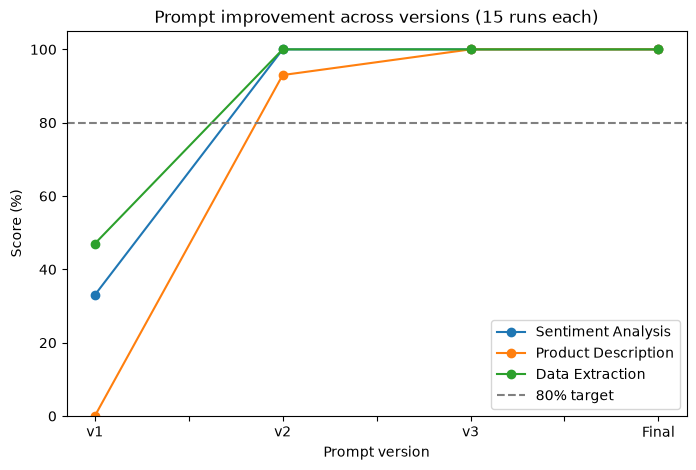

In [44]:
import matplotlib.pyplot as plt

versions = ["v1", "v2", "v3", "Final"]
ax = comparison.set_index("Task")[versions].T.plot(kind="line", marker="o", figsize=(8, 5))

ax.axhline(80, linestyle="--", color="gray", label="80% target")
ax.set_title("Prompt improvement across versions (15 runs each)")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Prompt version")
ax.set_ylim(0, 105)
ax.legend()
plt.show()

Final Report:

## Step 13: Final Evaluation and Comparison Report

### Final prompts

| Task | Final version | Techniques used |
|---|---|---|
| Sentiment Analysis | v3 | Clear instructions, fixed labels, output constraints, few-shot examples, rule for mixed messages |
| Product Description | v3.1 | Product facts, fixed structure, few-shot examples, word limits per bullet and sentence, banned vague words |
| Data Extraction | v3.1 | JSON format, fixed field names and values, Chain-of-Thought with clear rules per step |

### Final results (15 runs each, original inputs)

| Task | Metric | v1 | v2 | v3* | Final | Improvement |
|---|---|---|---|---|---|---|
| Sentiment Analysis | Exact-match consistency | 33% | 100% | 100% | 100% | +67 points |
| Product Description | Passes all rules | 0% | 93% | 100% | 100% | +100 points |
| Data Extraction | Consistency | 47% | 100% | 100% | 100% | +53 points |

*For Product Description and Data Extraction, the v3 column shows the corrected v3.1 versions.

- **Sentiment:** 15/15 answered exactly "Positive".
- **Product Description:** 15/15 passed all rules, with lengths between 56 and 72 words.
- **Data Extraction:** 15/15 returned valid, fully correct JSON.

The largest jump happened from v1 to v2 for every task: clear instructions, a defined output format and constraints solved most of the inconsistency. v3 techniques (few-shot and Chain-of-Thought) mainly improved quality and robustness on harder inputs.

### Success criteria

| Criterion | Status | Evidence |
|---|---|---|
| Identify failure patterns by running prompts multiple times | ✅ | Steps 3–5: v1 tested 5, 10 and 15 times. More runs revealed more failures and lower consistency. |
| Implement few-shot and Chain-of-Thought | ✅ | Few-shot in Steps 9 and 11, Chain-of-Thought in Step 10 |
| Measurable improvement in consistency | ✅ | All tasks improved by 53 to 100 percentage points |
| Adapt prompts for task variations | ✅ | Step 12: 13 variations tested, including sarcasm, German, missing information and other date formats |
| Final prompts >80% consistent across 15 runs | ✅ | All three final prompts: 100% |

### Key lessons

1. **Testing once is not enough.** v1 prompts looked fine after one run. Only repeated testing showed the inconsistency, and more runs revealed failure patterns that fewer runs missed.
2. **Most failures came from the prompt, not the model.** The model understood the tasks in v1 (the sentiment was always recognized as positive). It just didn't know what format or rules to follow.
3. **Clear output formats and constraints had the biggest effect.** Defining labels, JSON fields, structure and length raised consistency more than any advanced technique.
4. **Advanced techniques are not automatically better.** Few-shot examples showed a ceiling effect on easy inputs. Chain-of-Thought first made extraction worse (8/15), because the model applied a vague rule too literally. It only worked once each reasoning step had clear rules.
5. **Fixing one problem can create another.** Few-shot examples improved the product description quality but broke the length rule (7/15). Specific, countable rules (words per bullet) fixed it.
6. **Reading outputs matters as much as automatic checks.** Some failures passed every check: an invented compatibility claim ("with any computer"), and in Step 12 an invented feature and dropped features, while "exactly 3 bullets" still showed 5/5.

### Limitations

- The final 15-run scores use the original inputs only. Step 12 showed that the product description prompt still fails when a product has more or fewer than 3 features. A fix was suggested but not tested.
- Some metrics changed between versions: v1 extraction was measured on text, v2 onward on JSON. The v1 product score applies rules that v1 never asked for.
- Word-search checks have limits. Vague words ("perfect"), repetitive openings ("Ideal for...") and small invented claims ("gamers") still appeared in some product descriptions.
- Tests used one model (gpt-4o-mini) at temperature 0.7. Results may differ with other models or settings.

### Next steps
- Apply and test the "one bullet per feature" fix for the product description.
- Test with more varied and real customer inputs.
- Consider the API's built-in structured output (JSON mode) for data extraction, to guarantee valid JSON.